1. Import Library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

2. Data Retrieval

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Membaca dataset asli dari Google Drive

df = pd.read_csv('/content/drive/MyDrive/Penambangan Data/dataset_kasus_mahasiswa.csv')

# Menampilkan 5 data pertama
df.head()

,ID_Mahasiswa,Nama_Mahasiswa,Program_Studi,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
0,1001,Aditya Pratama,Sistem Informasi,Rendah,21.0,176.0,2000000,81.0,77.3
1,1002,Aisyah Saputra,Manajemen Rekayasa,Sedang,20.0,170.0,1.500.000,32.0,73.7
2,1003,Alif Wijaya,sistem informasi,Sedang,18.0,161.0,1000000,78.0,81.3
3,1004,Amalia Kusuma,Teknik Informatika,Sedang,21.0,164.0,3000000,38.0,64.6
4,1005,Andi Sari,Sistem Informasi,Tinggi,-20.0,177.0,2500000,68.0,94.2


3. Data Understanding

In [5]:
# Menampilkan ukuran dataset
print("Ukuran Dataset:", df.shape)

# Menampilkan informasi dataset
df.info()

# Menampilkan statistik deskriptif
df.describe(include='all')

Ukuran Dataset: (105, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID_Mahasiswa       105 non-null    int64  
 1   Nama_Mahasiswa     102 non-null    object 
 2   Program_Studi      101 non-null    object 
 3   Tingkat_Kepuasan   101 non-null    object 
 4   Usia               101 non-null    float64
 5   Tinggi_Badan       102 non-null    float64
 6   Uang_Saku_Bulanan  102 non-null    object 
 7   Jumlah_Login_LMS   101 non-null    float64
 8   Nilai_Akhir        101 non-null    float64
dtypes: float64(4), int64(1), object(4)
memory usage: 7.5+ KB


,ID_Mahasiswa,Nama_Mahasiswa,Program_Studi,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
count,105.000000,102,101,101,101.000000,102.000000,102,101.000000,101.000000
unique,NaN,97,12,8,NaN,NaN,12,NaN,NaN
top,NaN,Aditya Pratama,Sistem Informasi,Sedang,NaN,NaN,1500000,NaN,NaN
freq,NaN,2,44,44,NaN,NaN,22,NaN,NaN
mean,1049.333333,NaN,NaN,NaN,22.356436,160.690686,NaN,60.910891,79.819802
std,29.069435,NaN,NaN,NaN,22.805080,37.124308,NaN,57.744281,17.046577
min,1001.000000,NaN,NaN,NaN,-20.000000,1.600000,NaN,20.000000,-15.000000
25%,1025.000000,NaN,NaN,NaN,19.000000,161.000000,NaN,35.000000,72.800000
50%,1049.000000,NaN,NaN,NaN,21.000000,168.500000,NaN,54.000000,80.200000
75%,1074.000000,NaN,NaN,NaN,22.000000,176.000000,NaN,71.000000,88.700000


### 4. Data Cleansing

A. Mengidentifikasi kesalahan penulisan dan kategori

In [6]:
# Melihat kategori pada setiap variabel kategorik

print("Program Studi:")
print(df['Program_Studi'].value_counts(dropna=False))

print("\nTingkat Kepuasan:")
print(df['Tingkat_Kepuasan'].value_counts(dropna=False))

Program Studi:
Program_Studi
Sistem Informasi          44
Teknik Informatika        26
Manajemen Rekayasa        22
NaN                        4
sistem informasi           1
SISTEM INFORMASI           1
 Manajemen Rekayasa        1
  Teknik Informatika       1
Sistm Informasi            1
teknik informatika         1
Teknik Informatka          1
manajemen rekayasa         1
Manajmen Rekayasa          1
Name: count, dtype: int64

Tingkat Kepuasan:
Tingkat_Kepuasan
Sedang      44
Tinggi      34
Rendah      18
NaN          4
tinggi       1
Sedng        1
RENDAH       1
 Tinggi      1
Rendh        1
Name: count, dtype: int64


B. Mengidentifikasi redundant whitespace

In [7]:
# Memeriksa data yang memiliki spasi berlebih

for kolom in ['Nama_Mahasiswa', 'Program_Studi', 'Tingkat_Kepuasan']:
    print("\n", kolom)
    print(df[kolom].dropna().unique())


 Nama_Mahasiswa
['Aditya Pratama' 'Aisyah Saputra' 'Alif Wijaya' '  Amalia Kusuma  '
 'Andi Sari' 'Angga Putri' 'Anisa Hidayat' 'Arif Nugroho' 'Aulia Ramadhan'
 'Bagas Permata' 'Bayu Setiawan' 'Bella Santoso' 'Bima Lestari'
 'Cahya Rahmawati' 'Citra Fauzi' 'Dani Hakim' 'Dedi Maulana'
 'Devi Kurniawan' 'Dewi Utami' 'Dimas Firmansyah' '   Dina Susanto'
 'Dodi Handayani' 'Dwi Anggraini' 'Eka Puspitasari' 'Eko Yulianto'
 'Elsa Hartono' 'Endah Suryadi' 'Fajar Wibowo' 'Farah Hasanah'
 'Fauzan Prasetyo' 'Fikri Astuti' 'Fitri Maharani' 'Galih Budiman'
 'Gita Cahyono' 'Hadi Fitriani' 'Hana Hermawan' 'Hendra Irawan'
 'Ika Jatmiko' 'Ilham Kartini' 'Indah Lubis' 'Indra Mulyadi'
 'Intan Nasution' 'Irfan Oktaviani' 'Joko Pangestu' 'Kartika Qomariyah'
 'Kevin Riyadi' 'Kurnia Syahputra' 'Laila Tanjung' 'Lestari Pratama'
 'Lia Saputra' 'Lukman Wijaya' 'Maya Kusuma' 'Mega Sari' 'Melati Putri'
 'Miftah Hidayat' 'Muhammad Nugroho' 'Nadia Ramadhan' 'Nanda Permata'
 'Nia Santoso' 'Nisa Lestari' 'Novi Wulan

C. Mengidentifikasi missing value

In [8]:
# Menghitung jumlah missing value setiap kolom

df.isnull().sum()

,0
ID_Mahasiswa,0
Nama_Mahasiswa,3
Program_Studi,4
Tingkat_Kepuasan,4
Usia,4
Tinggi_Badan,3
Uang_Saku_Bulanan,3
Jumlah_Login_LMS,4
Nilai_Akhir,4


In [9]:
# Menampilkan baris yang memiliki missing value

df[df.isnull().any(axis=1)]

,ID_Mahasiswa,Nama_Mahasiswa,Program_Studi,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
13,1014,NaN,Sistem Informasi,Tinggi,19.0,179.0,2500000,44.0,89.1
15,1016,Citra Fauzi,NaN,Tinggi,19.0,167.0,3000000,72.0,85.9
17,1018,Dedi Maulana,Teknik Informatika,Rendah,NaN,155.0,1500000,35.0,75.8
20,1021,Dimas Firmansyah,Teknik Informatika,NaN,18.0,170.0,1500000,72.0,63.5
23,1024,Dwi Anggraini,Sistem Informasi,Rendah,21.0,NaN,1500000,58.0,88.7
24,1025,Eka Puspitasari,Teknik Informatika,Sedang,18.0,177.0,2000000,NaN,94.6
28,1029,Fajar Wibowo,Teknik Informatika,Rendah,20.0,177.0,NaN,28.0,94.0
30,1031,Fauzan Prasetyo,Teknik Informatika,Sedang,18.0,173.0,1500000,36.0,NaN
31,1032,NaN,Sistem Informasi,Sedang,21.0,179.0,1000000,26.0,77.5
44,1045,Irfan Oktaviani,Sistem Informasi,Sedang,NaN,159.0,3000000,84.0,76.9


D. Mengidentifikasi data duplikat

In [10]:
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 5


E. Mengidentifikasi impossible value

In [11]:
df.describe()

,ID_Mahasiswa,Usia,Tinggi_Badan,Jumlah_Login_LMS,Nilai_Akhir
count,105.000000,101.000000,102.000000,101.000000,101.000000
mean,1049.333333,22.356436,160.690686,60.910891,79.819802
std,29.069435,22.805080,37.124308,57.744281,17.046577
min,1001.000000,-20.000000,1.600000,20.000000,-15.000000
25%,1025.000000,19.000000,161.000000,35.000000,72.800000
50%,1049.000000,21.000000,168.500000,54.000000,80.200000
75%,1074.000000,22.000000,176.000000,71.000000,88.700000
max,1100.000000,245.000000,180.000000,410.000000,185.000000


## 5. Data Repair

A. Menghapus data duplikat

In [12]:
# Menghapus baris duplikat

df = df.drop_duplicates()

print("Jumlah data setelah menghapus duplikat:", df.shape[0])

Jumlah data setelah menghapus duplikat: 100


B. Memperbaiki redundant whitespace

In [13]:
# Menghilangkan spasi di awal dan akhir teks

df['Nama_Mahasiswa'] = df['Nama_Mahasiswa'].str.strip()
df['Program_Studi'] = df['Program_Studi'].str.strip()
df['Tingkat_Kepuasan'] = df['Tingkat_Kepuasan'].str.strip()

# Memeriksa hasil
df.head()

,ID_Mahasiswa,Nama_Mahasiswa,Program_Studi,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
0,1001,Aditya Pratama,Sistem Informasi,Rendah,21.0,176.0,2000000,81.0,77.3
1,1002,Aisyah Saputra,Manajemen Rekayasa,Sedang,20.0,170.0,1.500.000,32.0,73.7
2,1003,Alif Wijaya,sistem informasi,Sedang,18.0,161.0,1000000,78.0,81.3
3,1004,Amalia Kusuma,Teknik Informatika,Sedang,21.0,164.0,3000000,38.0,64.6
4,1005,Andi Sari,Sistem Informasi,Tinggi,-20.0,177.0,2500000,68.0,94.2


C. Memperbaiki kesalahan kapitalisasi

In [14]:
# Menyeragamkan kapitalisasi kategori

df['Program_Studi'] = df['Program_Studi'].str.title()

df['Tingkat_Kepuasan'] = df['Tingkat_Kepuasan'].str.title()

# Memeriksa kategori
print(df['Program_Studi'].value_counts(dropna=False))
print(df['Tingkat_Kepuasan'].value_counts(dropna=False))

Program_Studi
Sistem Informasi      43
Teknik Informatika    28
Manajemen Rekayasa    22
NaN                    4
Sistm Informasi        1
Teknik Informatka      1
Manajmen Rekayasa      1
Name: count, dtype: int64
Tingkat_Kepuasan
Sedang    42
Tinggi    34
Rendah    18
NaN        4
Sedng      1
Rendh      1
Name: count, dtype: int64


D. Memperbaiki kesalahan penulisan kategori

In [15]:
# Memperbaiki kesalahan penulisan Program Studi

df['Program_Studi'] = df['Program_Studi'].replace({
    'Sistm Informasi': 'Sistem Informasi',
    'Teknik Informatka': 'Teknik Informatika',
    'Manajmen Rekayasa': 'Manajemen Rekayasa'
})

# Memperbaiki kesalahan penulisan Tingkat Kepuasan

df['Tingkat_Kepuasan'] = df['Tingkat_Kepuasan'].replace({
    'Sedng': 'Sedang',
    'Rendh': 'Rendah'
})

# Memeriksa hasil
print(df['Program_Studi'].value_counts(dropna=False))
print(df['Tingkat_Kepuasan'].value_counts(dropna=False))

Program_Studi
Sistem Informasi      44
Teknik Informatika    29
Manajemen Rekayasa    23
NaN                    4
Name: count, dtype: int64
Tingkat_Kepuasan
Sedang    43
Tinggi    34
Rendah    19
NaN        4
Name: count, dtype: int64


E. Menyeragamkan satuan tinggi badan

In [16]:
# Mengubah tinggi badan dalam meter menjadi sentimeter

df.loc[
    df['Tinggi_Badan'] < 3,
    'Tinggi_Badan'
] = df.loc[
    df['Tinggi_Badan'] < 3,
    'Tinggi_Badan'
] * 100

# Memeriksa hasil
print(df['Tinggi_Badan'].describe())

count     97.000000
mean     169.030928
std        8.057674
min      155.000000
25%      162.000000
50%      170.000000
75%      176.000000
max      180.000000
Name: Tinggi_Badan, dtype: float64


F. Mengubah format uang saku menjadi numerik

In [17]:
# Menghilangkan tanda titik dan koma pada uang saku

df['Uang_Saku_Bulanan'] = (
    df['Uang_Saku_Bulanan']
    .astype('string')
    .str.replace('.', '', regex=False)
    .str.replace(',', '', regex=False)
)

# Mengubah tipe data menjadi numerik
df['Uang_Saku_Bulanan'] = pd.to_numeric(
    df['Uang_Saku_Bulanan'],
    errors='coerce'
)

# Memeriksa tipe data
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID_Mahasiswa       100 non-null    int64  
 1   Nama_Mahasiswa     97 non-null     object 
 2   Program_Studi      96 non-null     object 
 3   Tingkat_Kepuasan   96 non-null     object 
 4   Usia               96 non-null     float64
 5   Tinggi_Badan       97 non-null     float64
 6   Uang_Saku_Bulanan  97 non-null     Int64  
 7   Jumlah_Login_LMS   96 non-null     float64
 8   Nilai_Akhir        96 non-null     float64
dtypes: Int64(1), float64(4), int64(1), object(3)
memory usage: 7.9+ KB


G. Menangani impossible value

In [18]:
# Memeriksa usia tidak valid

print("Usia tidak valid:")
display(df[df['Usia'] < 0])
display(df[df['Usia'] > 100])

# Memeriksa nilai akhir tidak valid

print("Nilai akhir tidak valid:")
display(df[
    (df['Nilai_Akhir'] < 0) |
    (df['Nilai_Akhir'] > 100)
])

Usia tidak valid:


,ID_Mahasiswa,Nama_Mahasiswa,Program_Studi,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
4,1005,Andi Sari,Sistem Informasi,Tinggi,-20.0,177.0,2500000,68.0,94.2


,ID_Mahasiswa,Nama_Mahasiswa,Program_Studi,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
19,1020,Dewi Utami,Sistem Informasi,Sedang,245.0,168.0,2500000,58.0,90.6


Nilai akhir tidak valid:


,ID_Mahasiswa,Nama_Mahasiswa,Program_Studi,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
33,1034,Fitri Maharani,Manajemen Rekayasa,Sedang,20.0,176.0,2000000,32.0,-15.0
41,1042,Indah Lubis,Teknik Informatika,Sedang,20.0,169.0,3000000,56.0,185.0


In [19]:
# Mengganti impossible value menjadi NaN
df.loc[
    (df['Usia'] < 0) | (df['Usia'] > 100),
    'Usia'
] = np.nan

df.loc[
    (df['Nilai_Akhir'] < 0) | (df['Nilai_Akhir'] > 100),
    'Nilai_Akhir'
] = np.nan

print("Impossible value berhasil ditangani.")

Impossible value berhasil ditangani.


6. Data Missing Value

In [21]:
# Statistik deskriptif sebelum imputasi

df.describe()

,ID_Mahasiswa,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
count,100.000000,94.000000,97.000000,97.0,96.000000,94.000000
mean,1050.500000,20.521277,169.030928,2567010.309278,58.447917,79.713830
std,29.011492,1.794428,8.057674,4307593.141997,50.972411,9.697684
min,1001.000000,18.000000,155.000000,1000000.0,20.000000,62.500000
25%,1025.750000,19.000000,162.000000,1500000.0,35.000000,72.950000
50%,1050.500000,20.500000,170.000000,2000000.0,54.500000,79.950000
75%,1075.250000,22.000000,176.000000,2500000.0,69.500000,88.775000
max,1100.000000,23.000000,180.000000,35000000.0,410.000000,95.000000


In [23]:
# Mengisi missing value menggunakan mean

kolom_numerik = [
    'Usia',
    'Tinggi_Badan',
    'Uang_Saku_Bulanan',
    'Jumlah_Login_LMS',
    'Nilai_Akhir'
]

for kolom in kolom_numerik:
    df[kolom] = df[kolom].fillna(df[kolom].mean())

print("Missing value numerik berhasil ditangani.")

Missing value numerik berhasil ditangani.


In [24]:
# Mengisi missing value menggunakan modus

kolom_kategorik = [
    'Program_Studi',
    'Tingkat_Kepuasan'
]

for kolom in kolom_kategorik:
    df[kolom] = df[kolom].fillna(df[kolom].mode()[0])

print("Missing value kategorik berhasil ditangani.")

Missing value kategorik berhasil ditangani.


In [25]:
df['Nama_Mahasiswa'] = df['Nama_Mahasiswa'].fillna(
    'Tidak Diketahui'
)

In [26]:
# Memeriksa jumlah missing value setelah penanganan

print(df.isnull().sum())

print(
    "Total Missing Value:",
    df.isnull().sum().sum()
)

ID_Mahasiswa         0
Nama_Mahasiswa       0
Program_Studi        0
Tingkat_Kepuasan     0
Usia                 0
Tinggi_Badan         0
Uang_Saku_Bulanan    0
Jumlah_Login_LMS     0
Nilai_Akhir          0
dtype: int64
Total Missing Value: 0


7. Identifikasi Outlier

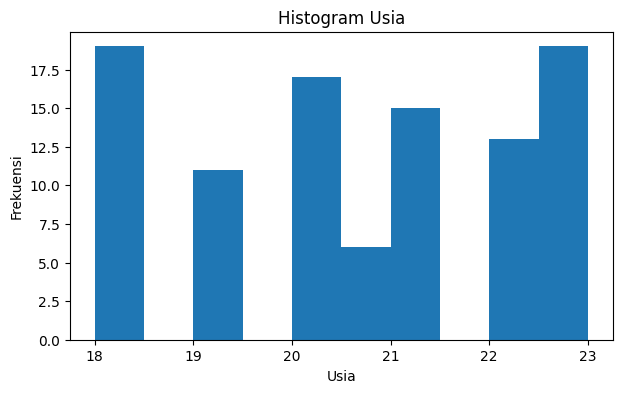

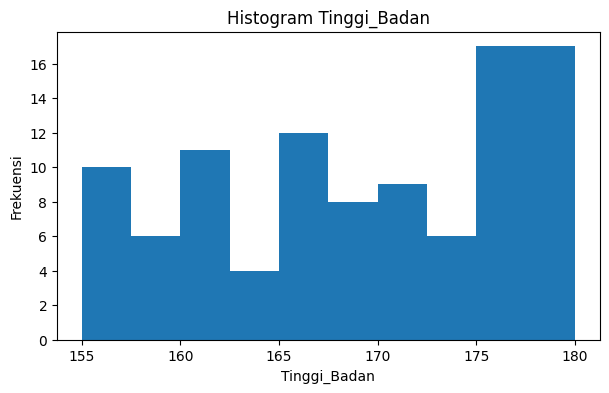

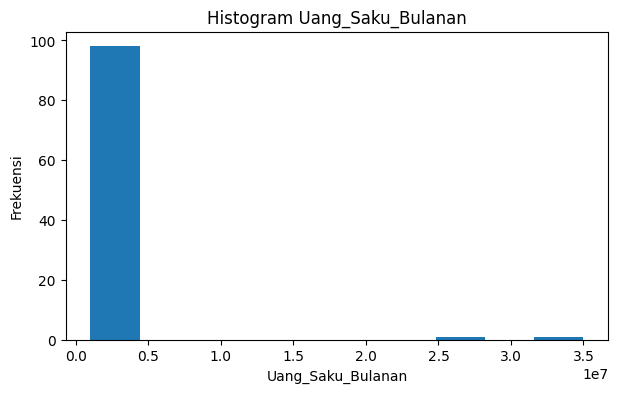

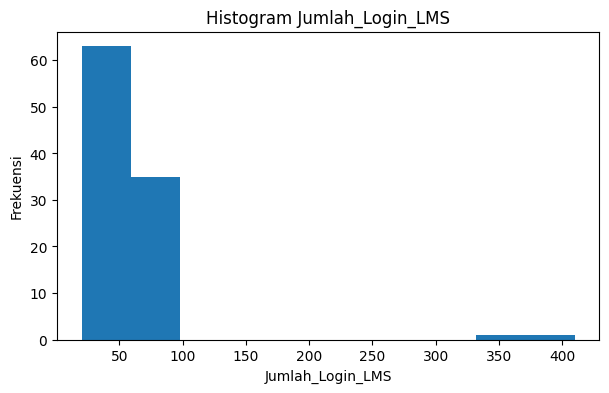

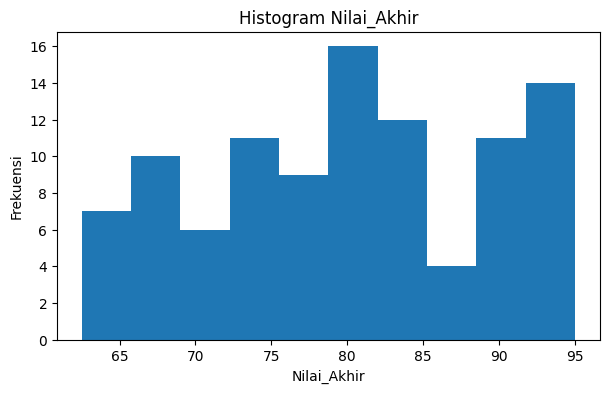

In [27]:
# Histogram variabel numerik

kolom_numerik = [
    'Usia',
    'Tinggi_Badan',
    'Uang_Saku_Bulanan',
    'Jumlah_Login_LMS',
    'Nilai_Akhir'
]

for kolom in kolom_numerik:
    plt.figure(figsize=(7, 4))

    plt.hist(df[kolom], bins=10)

    plt.title('Histogram ' + kolom)
    plt.xlabel(kolom)
    plt.ylabel('Frekuensi')

    plt.show()

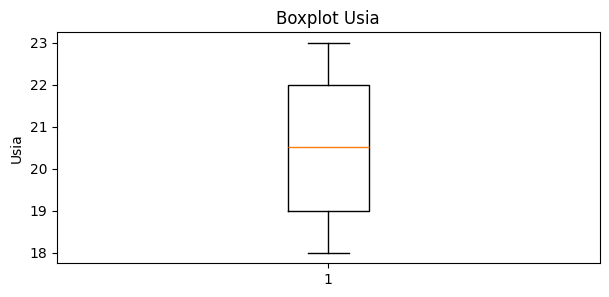

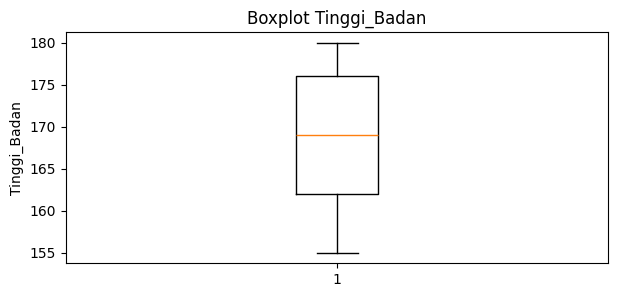

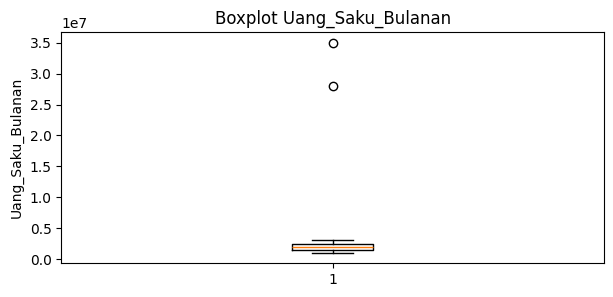

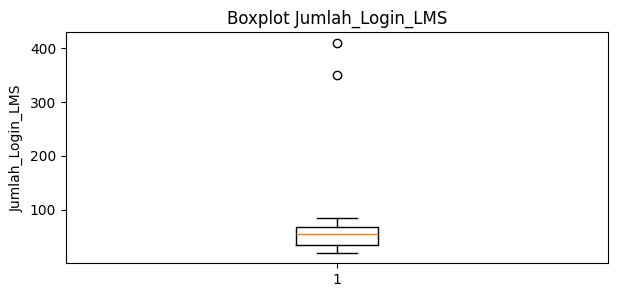

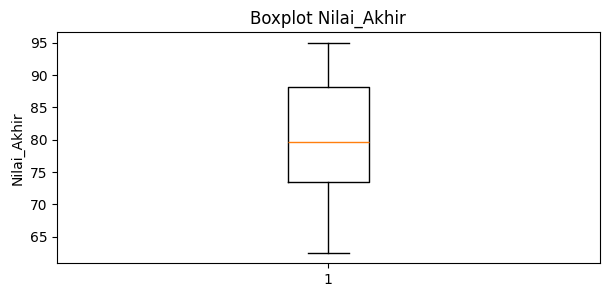

In [28]:
# Boxplot variabel numerik

for kolom in kolom_numerik:
    plt.figure(figsize=(7, 3))

    plt.boxplot(df[kolom])

    plt.title('Boxplot ' + kolom)
    plt.ylabel(kolom)

    plt.show()

8. Transforming Data – Normalization

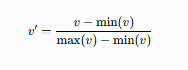

In [29]:
# Membuat salinan dataset untuk normalisasi

df_normalisasi = df.copy()

# Kolom numerik yang akan dinormalisasi
kolom_normalisasi = [
    'Usia',
    'Tinggi_Badan',
    'Uang_Saku_Bulanan',
    'Jumlah_Login_LMS',
    'Nilai_Akhir'
]

# Min-Max Normalization

for kolom in kolom_normalisasi:

    minimum = df_normalisasi[kolom].min()
    maksimum = df_normalisasi[kolom].max()

    df_normalisasi[kolom] = (
        (df_normalisasi[kolom] - minimum) /
        (maksimum - minimum)
    )

# Menampilkan hasil
df_normalisasi.head()

,ID_Mahasiswa,Nama_Mahasiswa,Program_Studi,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
0,1001,Aditya Pratama,Sistem Informasi,Rendah,0.600000,0.84,0.029412,0.156410,0.455385
1,1002,Aisyah Saputra,Manajemen Rekayasa,Sedang,0.400000,0.60,0.014706,0.030769,0.344615
2,1003,Alif Wijaya,Sistem Informasi,Sedang,0.000000,0.24,0.0,0.148718,0.578462
3,1004,Amalia Kusuma,Teknik Informatika,Sedang,0.600000,0.36,0.058824,0.046154,0.064615
4,1005,Andi Sari,Sistem Informasi,Tinggi,0.504255,0.88,0.044118,0.123077,0.975385


9. Transforming Data – Encoding

In [30]:
# One-Hot Encoding Program Studi

df_encoding = df_normalisasi.copy()

df_encoding = pd.get_dummies(
    df_encoding,
    columns=['Program_Studi'],
    dtype=int
)

df_encoding.head()

,ID_Mahasiswa,Nama_Mahasiswa,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir,Program_Studi_Manajemen Rekayasa,Program_Studi_Sistem Informasi,Program_Studi_Teknik Informatika
0,1001,Aditya Pratama,Rendah,0.600000,0.84,0.029412,0.156410,0.455385,0,1,0
1,1002,Aisyah Saputra,Sedang,0.400000,0.60,0.014706,0.030769,0.344615,1,0,0
2,1003,Alif Wijaya,Sedang,0.000000,0.24,0.0,0.148718,0.578462,0,1,0
3,1004,Amalia Kusuma,Sedang,0.600000,0.36,0.058824,0.046154,0.064615,0,0,1
4,1005,Andi Sari,Tinggi,0.504255,0.88,0.044118,0.123077,0.975385,0,1,0


In [31]:
# Label Encoding Tingkat Kepuasan

df_encoding['Tingkat_Kepuasan'] = (
    df_encoding['Tingkat_Kepuasan'].map({
        'Rendah': 1,
        'Sedang': 2,
        'Tinggi': 3
    })
)

df_encoding.head()

,ID_Mahasiswa,Nama_Mahasiswa,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir,Program_Studi_Manajemen Rekayasa,Program_Studi_Sistem Informasi,Program_Studi_Teknik Informatika
0,1001,Aditya Pratama,1,0.600000,0.84,0.029412,0.156410,0.455385,0,1,0
1,1002,Aisyah Saputra,2,0.400000,0.60,0.014706,0.030769,0.344615,1,0,0
2,1003,Alif Wijaya,2,0.000000,0.24,0.0,0.148718,0.578462,0,1,0
3,1004,Amalia Kusuma,2,0.600000,0.36,0.058824,0.046154,0.064615,0,0,1
4,1005,Andi Sari,3,0.504255,0.88,0.044118,0.123077,0.975385,0,1,0


10. Evaluasi hasil preprocessing

In [32]:
# Menampilkan 5 data pertama
display(df.head())

# Memeriksa ukuran dataset
print("Jumlah baris dan kolom:", df.shape)

# Memeriksa missing value
print("\nMissing Value:")
print(df.isnull().sum())

# Memeriksa duplikasi
print("\nJumlah duplikasi:", df.duplicated().sum())

# Statistik deskriptif setelah preprocessing
display(df.describe(include='all'))

,ID_Mahasiswa,Nama_Mahasiswa,Program_Studi,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
0,1001,Aditya Pratama,Sistem Informasi,Rendah,21.000000,176.0,2000000,81.0,77.3
1,1002,Aisyah Saputra,Manajemen Rekayasa,Sedang,20.000000,170.0,1500000,32.0,73.7
2,1003,Alif Wijaya,Sistem Informasi,Sedang,18.000000,161.0,1000000,78.0,81.3
3,1004,Amalia Kusuma,Teknik Informatika,Sedang,21.000000,164.0,3000000,38.0,64.6
4,1005,Andi Sari,Sistem Informasi,Tinggi,20.521277,177.0,2500000,68.0,94.2


Jumlah baris dan kolom: (100, 9)

Missing Value:
ID_Mahasiswa         0
Nama_Mahasiswa       0
Program_Studi        0
Tingkat_Kepuasan     0
Usia                 0
Tinggi_Badan         0
Uang_Saku_Bulanan    0
Jumlah_Login_LMS     0
Nilai_Akhir          0
dtype: int64

Jumlah duplikasi: 0


,ID_Mahasiswa,Nama_Mahasiswa,Program_Studi,Tingkat_Kepuasan,Usia,Tinggi_Badan,Uang_Saku_Bulanan,Jumlah_Login_LMS,Nilai_Akhir
count,100.000000,100,100,100,100.000000,100.000000,100.0,100.000000,100.000000
unique,NaN,98,3,3,NaN,NaN,<NA>,NaN,NaN
top,NaN,Tidak Diketahui,Sistem Informasi,Sedang,NaN,NaN,<NA>,NaN,NaN
freq,NaN,3,48,47,NaN,NaN,<NA>,NaN,NaN
mean,1050.500000,NaN,NaN,NaN,20.521277,169.030928,2567010.3,58.447917,79.713830
std,29.011492,NaN,NaN,NaN,1.739202,7.934649,4241824.499046,49.932049,9.399222
min,1001.000000,NaN,NaN,NaN,18.000000,155.000000,1000000.0,20.000000,62.500000
25%,1025.750000,NaN,NaN,NaN,19.000000,162.000000,1500000.0,35.000000,73.475000
50%,1050.500000,NaN,NaN,NaN,20.521277,169.030928,2000000.0,55.000000,79.713830
75%,1075.250000,NaN,NaN,NaN,22.000000,176.000000,2500000.0,68.250000,88.100000


11. Menyimpan hasil preprocessing

In [33]:
# Menyimpan dataset hasil preprocessing

df.to_csv(
    '/content/drive/MyDrive/Penambangan Data/dataset_mahasiswa_hasil_preprocessing.csv',
    index=False
)

print("Dataset hasil preprocessing berhasil disimpan!")

Dataset hasil preprocessing berhasil disimpan!
